# Métricas de deep learning · CNN 1D

A CNN percorre as colunas tabulares de cardiotocografia na ordem registrada no manifesto. Cada linha contém agregados de um exame. A ordem das colunas faz parte da receita.

A configuração inicial usa 60 épocas em cada fold e no refit. A imputação e a normalização são ajustadas no bloco de treino de cada fold. O notebook lê os artefatos do run e mantém a avaliação no TRAIN.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RUN_ID = None  # None escolhe o run CNN concluído mais recente.
runs = ROOT / "reports" / "runs"
prefix = "cnn_cv"
if RUN_ID is None:
    manifests = [
        json.loads(path.read_text(encoding="utf-8"))
        for path in runs.glob(f"*/experiments/{prefix}_manifest.json")
    ]
    if not manifests:
        raise FileNotFoundError("Gere o run com python -m saude_fetal.train --workflow cnn")
    manifest = max(manifests, key=lambda item: item["created_at"])
else:
    manifest = json.loads(
        (runs / RUN_ID / "experiments" / f"{prefix}_manifest.json").read_text(encoding="utf-8")
    )

run_dir = runs / manifest["run_id"]
metrics = run_dir / "metrics"
results = pd.read_csv(metrics / f"{prefix}_results.csv").iloc[0]
folds = pd.read_csv(metrics / f"{prefix}_fold_metrics.csv")
print(f"Run {manifest['run_id']} · MLflow {manifest['tracking_backend']}")
dataset = manifest['dataset'].get('name', 'fetal_health_reduced')
splitter = manifest.get('cv_splitter', 'StratifiedKFold')
print(f"Base {dataset} · {len(manifest['features'])} features · {splitter}")
display(pd.Series(manifest["cnn"], name="Configuração").to_frame())

def show_figure(suffix):
    path = run_dir / "figures" / f"{prefix}_{suffix}.png"
    display(Image(filename=str(path)))

Run 82dcf484c0434ce8a349fa585f7a558c · MLflow local
Base fetal_health_full · 21 features · StratifiedGroupKFold


,Configuração
epochs,60.000
batch_size,32.000
filters,16.000
kernel_size,2.000
dense_units,16.000
learning_rate,0.001


## Curvas de treinamento

Compare perda e acurácia de treino e validação ao longo das épocas. A faixa representa o desvio-padrão entre folds. O protocolo mede a decisão ao fim da última época.

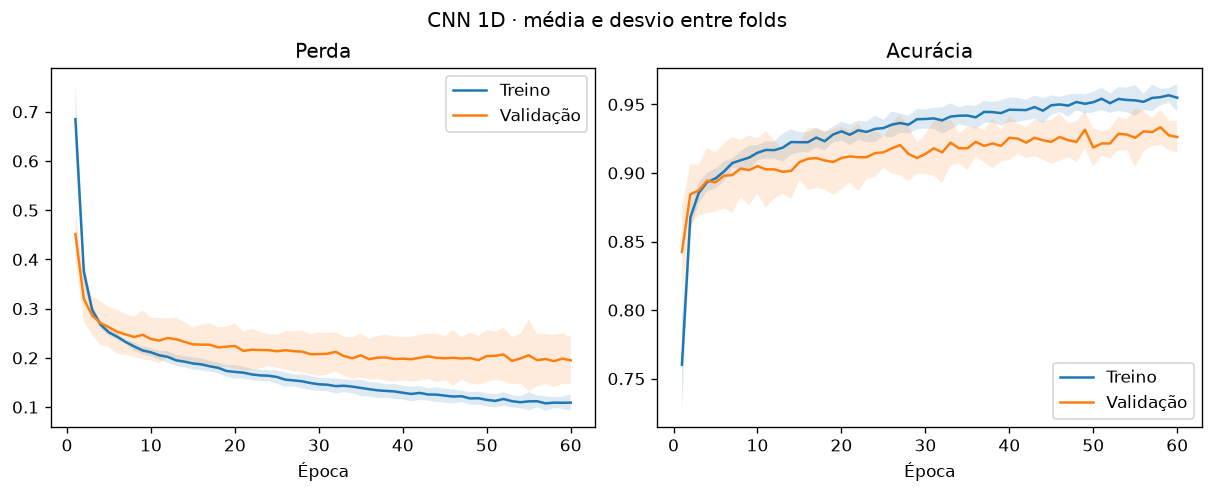

In [2]:
show_figure("learning_curves")

## Validação cruzada e desempenho por classe

As métricas por fold usam a decisão pela classe de maior score. O relatório OOF agrega os exames previstos nas respectivas partições de validação.

,train_f1_macro,val_f1_macro,val_recall_macro,val_precision_macro,val_recall_patologico,val_precision_patologico
fold,,,,,,
1,0.904,0.859,0.852,0.878,0.750,0.955
2,0.938,0.895,0.904,0.887,0.857,0.889
3,0.938,0.828,0.843,0.826,0.714,0.833
4,0.939,0.845,0.863,0.830,0.893,0.781
5,0.931,0.889,0.873,0.907,0.929,1.000


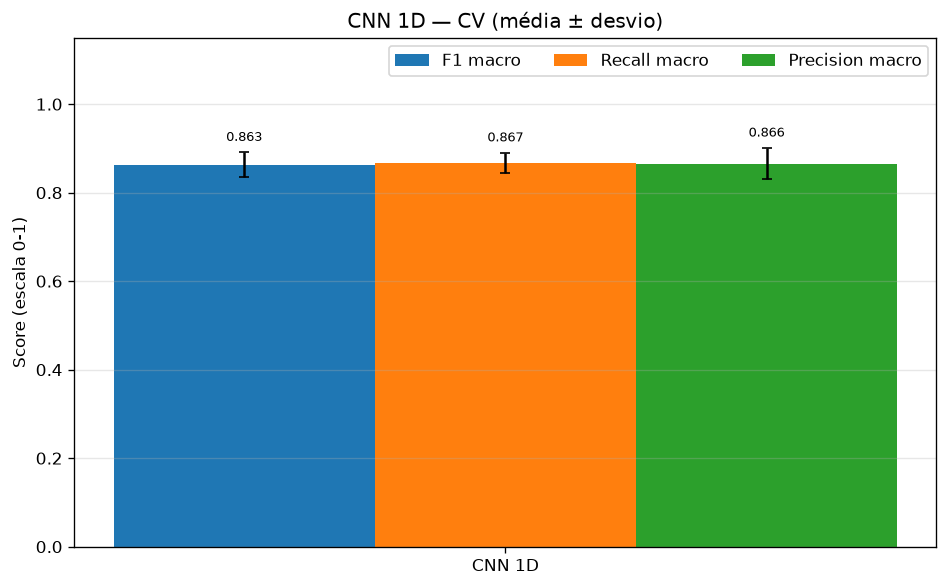

,precision,recall,f1-score,support
Normal,0.969,0.956,0.963,1321.0
Suspeito,0.732,0.816,0.772,234.0
Patologico,0.885,0.829,0.856,140.0
macro avg,0.862,0.867,0.863,1695.0
weighted avg,0.930,0.926,0.927,1695.0


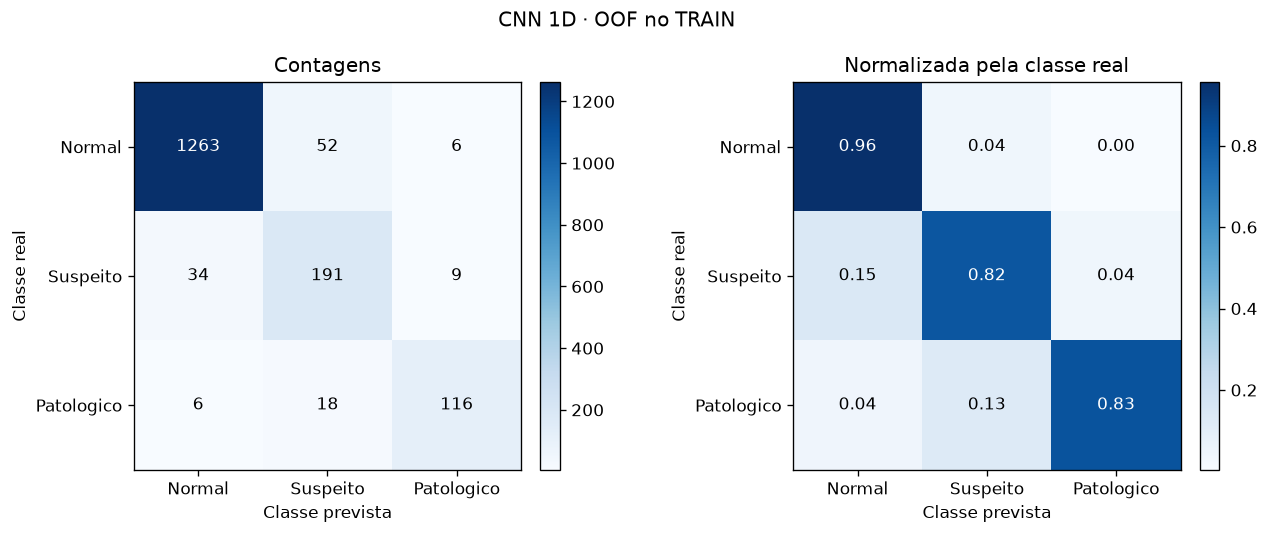

F1 macro médio na CV de **86.3%** e recall patológico médio de **82.9%**.

In [3]:
display(folds.set_index("fold")[
    ["train_f1_macro", "val_f1_macro", "val_recall_macro", "val_precision_macro",
     "val_recall_patologico", "val_precision_patologico"]
].round(3))
show_figure("macro_metrics")
report = json.loads((metrics / f"{prefix}_oof_classification_report.json").read_text(encoding="utf-8"))
class_report = pd.DataFrame({key: value for key, value in report.items() if isinstance(value, dict)}).T
display(class_report.round(3))
show_figure("confusion_oof")
display(Markdown(
    f"F1 macro médio na CV de **{results['cv_f1_macro_mean']:.1%}** e "
    f"recall patológico médio de **{results['cv_recall_patologico_mean']:.1%}**."
))

## Scores patológicos fora da amostra

As curvas tratam Patológico contra as demais classes. A linha horizontal marca a prevalência no TRAIN. A AP mede a ordenação dos scores. O recall na tabela mede as decisões por argmax.

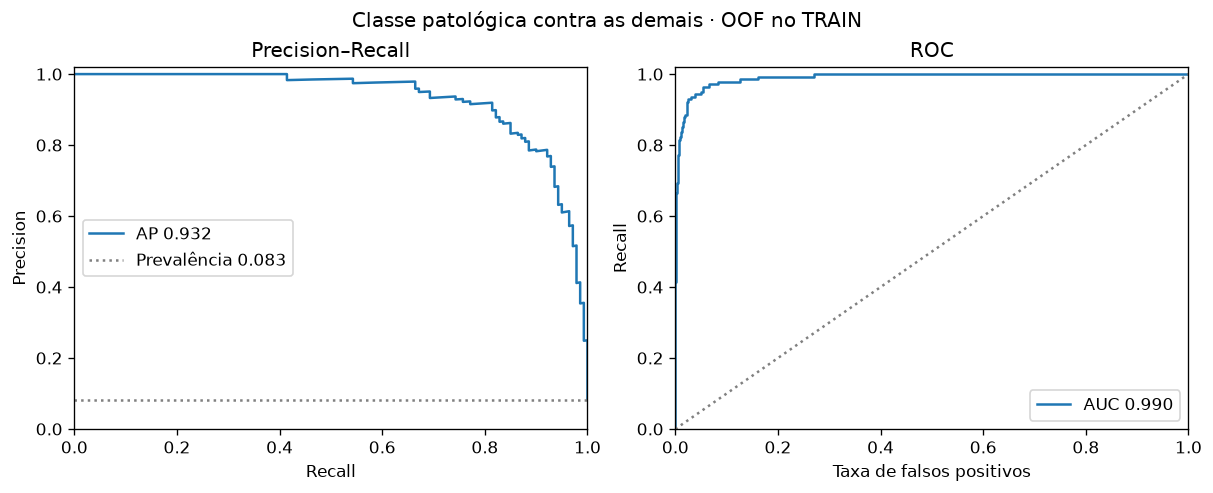

,OOF
oof_ap_patologico,0.932
oof_roc_auc_patologico,0.990
oof_log_loss,0.195


In [4]:
show_figure("critical_pr_roc")
display(results[["oof_ap_patologico", "oof_roc_auc_patologico", "oof_log_loss"]].astype(float).round(3).to_frame("OOF"))

## Refit e avaliação final

O modelo registrado no MLflow foi reajustado no TRAIN completo com a mesma configuração. O TEST permanece reservado para uma avaliação posterior da receita congelada.